# Latihan Eksplorasi Data – Nilai Bruto Transaksi
Siklus EDA: Pertanyaan → Eksplorasi → Temuan → So What → What Next

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
data=pd.read_excel(r'C:\VED\codeVED3\(2026)7. Data Studi Kasus.xlsx')
data.head(9)

,Txn_ID,Tanggal,Produk_ID,Kota,Channel,Qty,Harga/unit,Diskon,Status,HPP,laba,DISKON,bruto
0,T001,2026-01-08,P01,Surakarta,Store,8,18000,0.00,Selesai,11000,56000,144000,144000
1,T002,2026-01-08,P02,Solo,Online,6,25000,0.10,Selesai,16000,39000,135000,150000
2,T003,2026-02-08,P03,Surakarta,Online,4,30000,0.10,Selesai,18500,34000,108000,120000
3,T004,2026-02-08,P01,Sukoharjo,Store,10,18000,0.00,Selesai,11000,70000,180000,180000
4,T005,2026-03-08,P04,Solo,Online,5,22000,0.05,Return,13500,37000,104500,110000
5,T006,2026-03-08,P02,Surakarta,Store,3,25000,0.00,Cancel,16000,27000,75000,75000
6,T007,2026-04-08,P03,Sukoharjo,Online,40,30000,0.00,Selesai,18500,460000,1200000,1200000
7,T008,2026-04-08,P01,Solo,Online,7,18000,0.10,Selesai,11000,36400,113400,126000
8,T009,2026-05-08,P04,Sukoharjo,Store,1,22000,0.00,Selesai,13500,8500,22000,22000


## Looping 1: EDA Univariat
**Pertanyaan:** Bagaimana distribusi nilai bruto transaksi?

count    9.000000e+00
mean     2.363333e+05
std      3.642527e+05
min      2.200000e+04
25%      1.100000e+05
50%      1.260000e+05
75%      1.500000e+05
max      1.200000e+06
Name: bruto, dtype: float64
Skewness: 2.907491893271248
Kurtosis: 8.60400106840922
IQR: 40000.0 | batas pencilan: 50000.0 - 210000.0
  Txn_ID       Kota Channel  Qty    bruto
6   T007  Sukoharjo  Online   40  1200000
8   T009  Sukoharjo   Store    1    22000


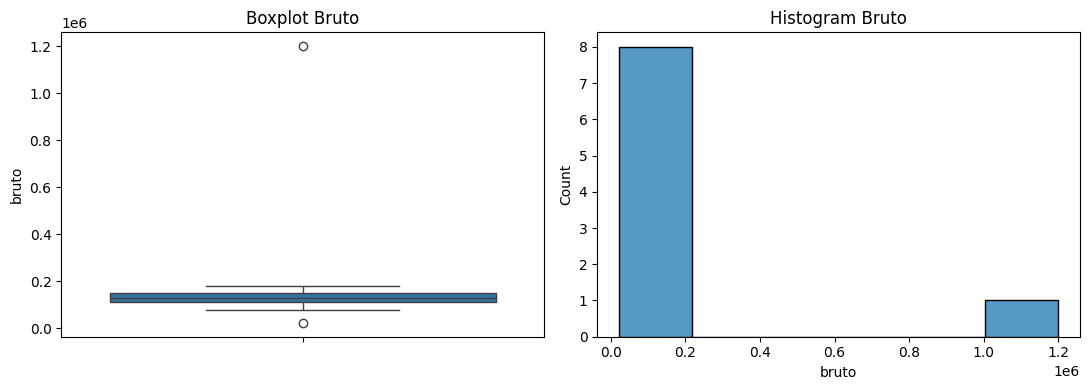

In [2]:
bruto=data['bruto']
print(bruto.describe())
print('Skewness:',bruto.skew()); print('Kurtosis:',bruto.kurt())
Q1,Q3=bruto.quantile(.25),bruto.quantile(.75); IQR=Q3-Q1
bb,ba=Q1-1.5*IQR,Q3+1.5*IQR
print('IQR:',IQR,'| batas pencilan:',bb,'-',ba)
print(data[(bruto<bb)|(bruto>ba)][['Txn_ID','Kota','Channel','Qty','bruto']])
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.boxplot(y=bruto,ax=ax[0]); ax[0].set_title('Boxplot Bruto')
sns.histplot(bruto,bins=6,ax=ax[1]); ax[1].set_title('Histogram Bruto')
plt.tight_layout(); plt.show()

**Temuan:** 8 dari 9 transaksi bernilai Rp22.000–Rp180.000 (median Rp126.000), tetapi ada satu nilai ekstrem T007 = Rp1.200.000 (di luar batas pencilan Rp210.000). Mean (Rp236.333) jauh di atas median; skewness = 2,91 (miring kanan kuat), kurtosis = 8,60 (ekor sangat berat).

**So What:** Distribusi sangat miring ke kanan; rata-rata tidak representatif, median lebih tepat. T007 (Qty 40) sendirian menyumbang 56,4% total bruto.

**What Next:** Verifikasi T007 valid/tidak, lalu bandingkan bruto per kota (bivariat).

## Looping 2: EDA Bivariat
**Pertanyaan:** Bagaimana perbedaan nilai bruto transaksi ditinjau dari kota penjualan? (data dianggap bersih → semua 9 transaksi dipakai apa adanya)

,Frekuensi,Total,Mean,Median,Std,Min,Max,Kontribusi (%)
Kota,,,,,,,,
Solo,3,386000,128666.67,126000.0,20132.89,110000,150000,18.15
Sukoharjo,3,1402000,467333.33,180000.0,639407.02,22000,1200000,65.91
Surakarta,3,339000,113000.00,120000.0,35028.56,75000,144000,15.94


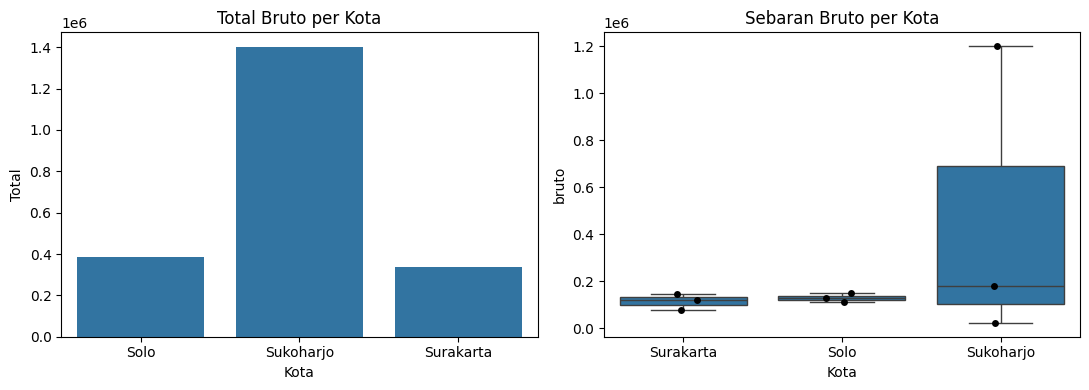

,count,sum,mean,median
Kota,,,,
Solo,3,386000,128666.666667,126000.0
Sukoharjo,2,202000,101000.000000,101000.0
Surakarta,3,339000,113000.000000,120000.0


In [3]:
ring=data.groupby('Kota')['bruto'].agg(Frekuensi='count',Total='sum',Mean='mean',Median='median',Std='std',Min='min',Max='max')
ring['Kontribusi (%)']=(ring['Total']/ring['Total'].sum()*100).round(2)
display(ring.round(2))
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.barplot(data=ring.reset_index(),x='Kota',y='Total',errorbar=None,ax=ax[0]); ax[0].set_title('Total Bruto per Kota')
sns.boxplot(data=data,x='Kota',y='bruto',ax=ax[1]); sns.stripplot(data=data,x='Kota',y='bruto',color='k',ax=ax[1]); ax[1].set_title('Sebaran Bruto per Kota')
plt.tight_layout(); plt.show()
# sensitivitas: tanpa T007
display(data[data.Txn_ID!='T007'].groupby('Kota')['bruto'].agg(['count','sum','mean','median']))

**Temuan:** Sukoharjo total Rp1.402.000 (65,9%), Solo Rp386.000 (18,1%), Surakarta Rp339.000 (15,9%). Rata-rata per transaksi: Sukoharjo Rp467.333, Solo Rp128.667, Surakarta Rp113.000. Median ketiganya mirip kecuali Sukoharjo (Rp180.000).

**So What:** Keunggulan Sukoharjo hampir seluruhnya karena T007. Tanpa T007, Sukoharjo menjadi yang terendah (total Rp202.000; rata-rata Rp101.000) dan ketiga kota nilainya berdekatan. Uji Kruskal–Wallis p = 0,67 (n = 3 per kota, indikatif saja): tidak ada bukti perbedaan nyata.

**What Next:** Periksa komposisi channel di tiap kota (multivariat).

Channel,Online,Store,Total
Kota,,,
Solo,386000,0,386000
Sukoharjo,1200000,202000,1402000
Surakarta,120000,219000,339000
Total,1706000,421000,2127000


Channel,Online,Store,Total
Kota,,,
Solo,3,0,3
Sukoharjo,1,2,3
Surakarta,1,2,3
Total,5,4,9


Channel,Online,Store,Rata-rata
Kota,,,
Solo,128667.0,NaN,128667.0
Sukoharjo,1200000.0,101000.0,467333.0
Surakarta,120000.0,109500.0,113000.0
Rata-rata,341200.0,105250.0,236333.0


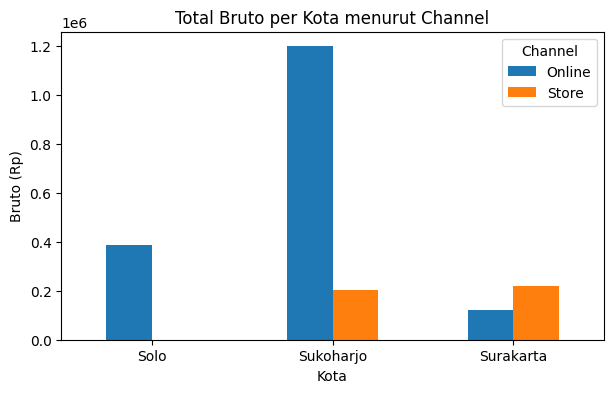

Channel,Online,Store,All
Kota,,,
Solo,386000,0,386000
Sukoharjo,0,202000,202000
Surakarta,120000,219000,339000
All,506000,421000,927000


In [4]:
piv=data.pivot_table(values='bruto',index='Kota',columns='Channel',aggfunc='sum',fill_value=0,margins=True,margins_name='Total')
display(piv)
display(data.pivot_table(values='bruto',index='Kota',columns='Channel',aggfunc='count',fill_value=0,margins=True,margins_name='Total'))
display(data.pivot_table(values='bruto',index='Kota',columns='Channel',aggfunc='mean',margins=True,margins_name='Rata-rata').round(0))
piv.drop(index='Total',columns='Total').plot(kind='bar',figsize=(7,4),title='Total Bruto per Kota menurut Channel'); plt.ylabel('Bruto (Rp)'); plt.xticks(rotation=0); plt.show()
import plotly.express as px
px.treemap(data,path=['Kota','Channel'],values='bruto',title='Treemap Bruto: Kota > Channel').show()
# sensitivitas tanpa T007
display(data[data.Txn_ID!='T007'].pivot_table(values='bruto',index='Kota',columns='Channel',aggfunc='sum',fill_value=0,margins=True))

**Temuan:** Ya, pola channel berbeda antar kota.
- Solo: 100% Online (Rp386.000), tidak ada Store.
- Sukoharjo: Online Rp1.200.000 (T007) vs Store Rp202.000 (2 transaksi).
- Surakarta: Store Rp219.000 (2 transaksi) > Online Rp120.000 (1 transaksi).

**So What:** Di Sukoharjo Online mendominasi (85,6%) karena T007; tanpa T007 Sukoharjo hanya Store. Di Surakarta Store lebih besar. Rata-rata per transaksi Store stabil (Rp101.000–Rp109.500), Online berfluktuasi. Setiap sel hanya 0–3 transaksi sehingga pola ini belum dapat digeneralisasi.

**What Next:** Verifikasi T007, tambah data, pertimbangkan Solo = Surakarta (nama kota sama), tambahkan Status (Return/Cancel) dan Produk, dan uji statistik bila sampel sudah memadai.